# Week 06: Stats for Business: Is the Price Right?

You just joined the pricing team at a car-listing marketplace. Your manager has a few questions and one rule: **every claim needs a number, and every number needs a reason to trust it.**

**Data:** `cars.csv`: about 12,000 car trims (1990–2017) with specs and sticker price (MSRP). Source: [Car Features and MSRP (Kaggle)](https://www.kaggle.com/datasets/CooperUnion/cardataset). It's real data, so it's messy.

**What you'll practice** (all from this week's lecture):
- Cleaning before describing
- Mean vs median, skew, log transforms
- z-scores
- Bootstrap confidence intervals
- One- and two-sample tests, and picking the right one
- Confounding, and significant vs important

**How to answer:** Fill in the code cells, then write 1–3 sentences in each **Answer:** cell. Code without an interpretation is only half the job.

Plan for about 2–3 hours. 🚀 questions are optional stretch.

## Setup

In [1]:
# run this first if you dont have them installed in your env
!pip install pandas numpy matplotlib scipy

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", None)
rng = np.random.default_rng(42)  # use rng for all random sampling so your results are reproducible

df = pd.read_csv("../data/cars.csv")
print(df.shape)
df.head()

(11914, 15)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,18,3916,34500


---
## Part 1: Can you trust this data?

### Q1. Find the problems before you average anything

This dataset has **at least five** real problems. Find them, fix or flag each one, and build a cleaned DataFrame called `clean`. You'll use `clean` for the rest of the notebook.

Use your Week 02 cleaning checklist. Some nudges, in no particular order:
- Count things twice.
- The most common value in a column can be more suspicious than the largest one.
- Would you print every max value in a sales brochure?
- Missing values usually have a reason. *Who* is missing?
- Is every number in a column measured in the same unit?
- Does every column vary at the level you'd expect?
- Not everything weird is wrong.

For each problem, decide: **drop it, set it to NaN, flag it, or leave it**. Dropping whole rows is the last resort, because a row with a bad price may still have a good MPG.

In [2]:
# Explore here. Add as many cells as you need.
# Useful: .duplicated(), .value_counts(), .describe(), .isna().sum(), .nlargest(), .groupby(...).nunique()
# df.shape

clean = df.copy()
clean.duplicated().sum()
clean = clean.drop_duplicates()
clean.isna().sum()



Make                  0
Model                 0
Year                  0
Engine Fuel Type      3
Engine HP            69
Engine Cylinders     30
Transmission Type     0
Driven_Wheels         0
Number of Doors       6
Vehicle Size          0
Vehicle Style         0
highway MPG           0
city mpg              0
Popularity            0
MSRP                  0
dtype: int64

In [3]:
clean['Transmission Type'].value_counts()
clean['Transmission Type'] = clean['Transmission Type'].replace('UNKNOWN', np.nan)


In [4]:
clean['MSRP'].value_counts()
clean['MSRP'] = clean['MSRP'].replace('2000', np.nan)

In [5]:
clean['Engine Cylinders'].value_counts()

Engine Cylinders
4.0     4361
6.0     4288
8.0     1964
12.0     228
5.0      169
10.0      65
0.0       56
3.0       30
16.0       3
Name: count, dtype: int64

In [6]:
clean['Engine Fuel Type'].value_counts()
clean.loc[(clean['Engine Fuel Type'] == 'electric') & (clean['Engine Cylinders'] != 0.0)] 
clean.loc[(clean['Engine Fuel Type'] == 'electric') & (clean['Engine Cylinders'] != 0.0), 'Engine Cylinders'] = 0.0
clean.loc[(clean['Engine Fuel Type'] == 'electric') & (clean['Engine Cylinders'] == 0.0)] 

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
539,FIAT,500e,2015,electric,NaN,0.0,DIRECT_DRIVE,front wheel drive,2.0,Compact,2dr Hatchback,108,122,819,31800
540,FIAT,500e,2016,electric,NaN,0.0,DIRECT_DRIVE,front wheel drive,2.0,Compact,2dr Hatchback,103,121,819,31800
541,FIAT,500e,2017,electric,NaN,0.0,DIRECT_DRIVE,front wheel drive,2.0,Compact,2dr Hatchback,103,121,819,31800
1680,Mercedes-Benz,B-Class Electric Drive,2015,electric,177.0,0.0,DIRECT_DRIVE,front wheel drive,4.0,Compact,4dr Hatchback,82,85,617,41450
1681,Mercedes-Benz,B-Class Electric Drive,2016,electric,177.0,0.0,DIRECT_DRIVE,front wheel drive,4.0,Compact,4dr Hatchback,82,85,617,41450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9868,Chevrolet,Spark EV,2014,electric,140.0,0.0,DIRECT_DRIVE,front wheel drive,4.0,Compact,4dr Hatchback,109,128,1385,27010
9869,Chevrolet,Spark EV,2015,electric,140.0,0.0,DIRECT_DRIVE,front wheel drive,4.0,Compact,4dr Hatchback,109,128,1385,25170
9870,Chevrolet,Spark EV,2015,electric,140.0,0.0,DIRECT_DRIVE,front wheel drive,4.0,Compact,4dr Hatchback,109,128,1385,25560
9871,Chevrolet,Spark EV,2016,electric,140.0,0.0,DIRECT_DRIVE,front wheel drive,4.0,Compact,4dr Hatchback,109,128,1385,25510


In [7]:
clean.loc[(clean['Model'] == 'RX-8') | (clean['Model'] == 'RX-7')].shape[0] 

20

In [8]:
clean['Popularity'].shape[0]

11194

In [9]:
clean['highway MPG'].value_counts()
row_index = clean[clean['highway MPG'] == 354].index[0]
clean.at[row_index, 'highway MPG'] = np.nan
clean

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26.0,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28.0,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28.0,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28.0,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28.0,18,3916,34500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11909,Acura,ZDX,2012,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,Midsize,4dr Hatchback,23.0,16,204,46120
11910,Acura,ZDX,2012,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,Midsize,4dr Hatchback,23.0,16,204,56670
11911,Acura,ZDX,2012,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,Midsize,4dr Hatchback,23.0,16,204,50620
11912,Acura,ZDX,2013,premium unleaded (recommended),300.0,6.0,AUTOMATIC,all wheel drive,4.0,Midsize,4dr Hatchback,23.0,16,204,50920


**Cleaning log:** fill in one row per problem.

| # | Problem | How I found it | Rows affected | What I did | Why |
|---|---|---|---|---|---|
| 1 | Duplicate Rows| clean.duplicated().sum() | 720 | Dropped | They would inflate data |
| 2 | N/A Values | clean.isna().sum() | 108 | Nothing | Wouldn't be counted |
| 3 | Unkown Transmission Type | clean['Transmission Type'].value_counts() | 12 | set to NaN | Won't be counted |
| 4 | Price of 2000 for MSRP | clean['MSRP'].value_counts() | 747 | set to NaN | Placeholder values will mess with data |
| 5 | NaN EV Engine Cylinders  | clean.loc[(df['Engine Fuel Type'] == 'electric') & (clean['Engine Cylinders'] != 0.0 | 10 | Replaced NaN Values with 0.0 | Truthful Data |
| 6 | NaN Non-EV Cylinders  | Claude to find out | 20 | Nothing | Although these specific cars use a rotary engine which don't have cylinders, it is more work to include  |
| 7 | Popularity  | Looking at csv file | All | Ignored | Does not tell you anything about how popular an individual model is |
| 8 | Highway MPG 354  | clean['Highway MPG'].value_counts() | 1 | set to NaN | The typo 354 could be 34 or 35 which means guesswork. I don't have a good reason to guess  |

In [10]:
# Build your cleaned DataFrame. Start from a copy so df stays untouched.
#clean = df.copy()
clean.columns = clean.columns.str.strip().str.lower().str.replace(" ", "_")  # freebie: snake_case names
clean

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26.0,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28.0,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28.0,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28.0,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28.0,18,3916,34500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11909,Acura,ZDX,2012,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,Midsize,4dr Hatchback,23.0,16,204,46120
11910,Acura,ZDX,2012,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,Midsize,4dr Hatchback,23.0,16,204,56670
11911,Acura,ZDX,2012,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,Midsize,4dr Hatchback,23.0,16,204,50620
11912,Acura,ZDX,2013,premium unleaded (recommended),300.0,6.0,AUTOMATIC,all wheel drive,4.0,Midsize,4dr Hatchback,23.0,16,204,50920


In [11]:
# Checkpoint: run this before moving on.
print(clean.shape)
print(clean.isna().sum()[clean.isna().sum() > 0])
# Fewer than ~10,000 rows? You probably dropped too much. Go back and use NaN or a flag instead.

(11194, 15)
engine_fuel_type      3
engine_hp            69
engine_cylinders     20
transmission_type    12
number_of_doors       6
highway_mpg           1
dtype: int64


---
## Part 2: Describe

### Q2. What does a "typical" car cost?

Your manager wants one number for "typical price" on the homepage.

a) Compute the mean and median MSRP. Which is bigger, and why?

b) Plot a histogram of MSRP, then a histogram of `np.log10(msrp)`. Describe each shape in a few words.

c) What percent of cars cost more than the mean?

d) Which number belongs on the homepage? Why?

Mean MSRP: $41,933.29
Median MSRP: $30,675.00


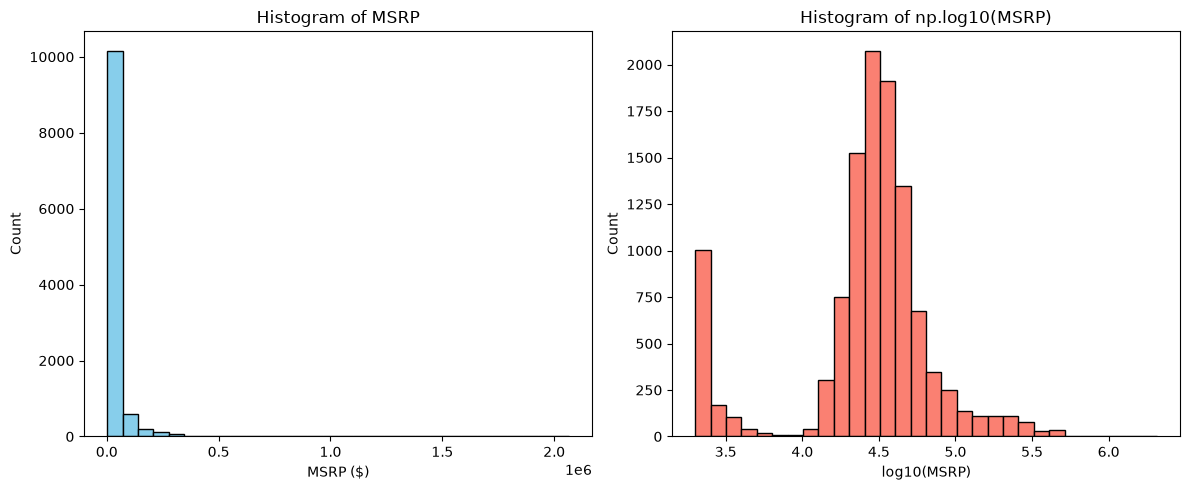

26.68%


In [12]:
# a) mean and median
clean.dropna(subset=['msrp'], inplace=True)
mean = clean['msrp'].mean()
median = clean['msrp'].median()
print(f"Mean MSRP: ${mean:,.2f}")
print(f"Median MSRP: ${median:,.2f}")
# b) two histograms side by side (plt.subplots(1, 2))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(clean['msrp'], bins=30, color='skyblue', edgecolor='black')
axes[0].set_title('Histogram of MSRP')
axes[0].set_xlabel('MSRP ($)')
axes[0].set_ylabel('Count')

axes[1].hist(np.log10(clean['msrp']), bins=30, color='salmon', edgecolor='black')
axes[1].set_title('Histogram of np.log10(MSRP)')
axes[1].set_xlabel('log10(MSRP)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()
# c) share of cars above the mean
percent_above_mean = (clean['msrp'] > mean).mean()
print(f"{percent_above_mean:.2%}")
#print(percent_above_mean)

**Answer:** The median should be on the homepage. Better representation of the usual car price at MSRP

### Q3. Fuel-efficient *for its size*?

Two 2017 cars:
- **Honda Civic** (Compact): 42 highway MPG
- **Volvo S90** (Large): 34 highway MPG

The Civic wins on raw MPG, but large cars are heavier. Which one is more impressive *for its class*?

a) For 2017 cars (only the MPG values you trust after Q1), compute the mean and standard deviation of highway MPG for each `vehicle_size`.

b) Compute each car's z-score within its own size class.

c) Which is more fuel-efficient for its class? How unusual is each one?

In [13]:
# a) mean and std of highway_mpg by vehicle_size, 2017 only
cars_2017 = clean[clean['year'] == 2017]
cars_2017.groupby('vehicle_size')['highway_mpg'].agg(['mean','std'])

,mean,std
vehicle_size,,
Compact,31.994197,10.784983
Large,22.991453,3.491184
Midsize,29.410658,5.452292


In [14]:
# b) z = (value - class mean) / class std
civic_z_score = (42 - 31.994) / 10.784
volvo_z_score = (34 - 22.991 ) / 3.491

print(f"{civic_z_score:.2f}")
print(f"{volvo_z_score:.2f}")

0.93
3.15


**Answer:** The Volvo S90 is more fuel efficient for it's class. What's strange is that its standard deviation of 3.15 sits three standard deviations above the overall average. The Honda Civic's standard deviation is not unusual as it is typical.

---
## Part 3: Uncertainty

### Q4. How sure are we about the median price?

The 2017 cars are one snapshot of the market. With a slightly different set of cars, the median would move. A bootstrap shows how much.

a) Compute the median MSRP of 2017 cars.

b) Bootstrap it: resample the 2017 prices **with replacement** 5,000 times and take the median each time. Plot the 5,000 medians and report the 95% interval (2.5th and 97.5th percentiles).

c) Repeat for 2017 cars from **one make** with fewer than 50 cars that year (your choice). Is the interval wider or narrower? Why?

d) Explain the interval from (b) in one sentence a manager would understand.

Median MSRP (2017): $36,738


95% interval: (35,940, 37,683)  width = 1,743


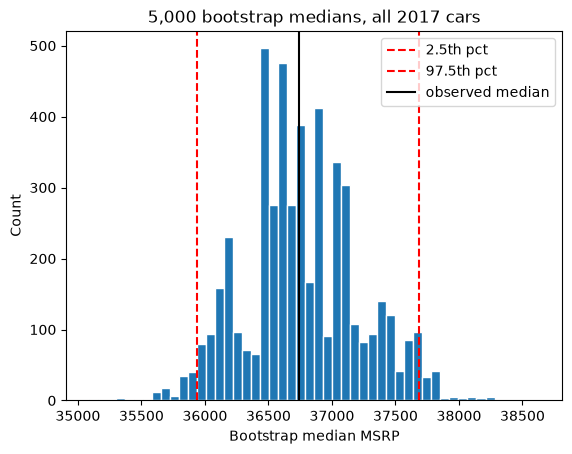

make
Subaru        46
Lincoln       46
Kia           43
Hyundai       42
Buick         39
Acura         36
Lexus         34
Mitsubishi    29
Infiniti      28
Porsche       25
Chrysler      24
Mazda         24
Volvo         23
FIAT          19
Land Rover    11
Maserati      10
Genesis        3
Lotus          1
Name: count, dtype: int64
Hyundai (n=42): median 26,850, 95% interval (24,125, 30,988), width = 6,862
All 2017 cars n: 1624
Hyundai 2017 n: 42


In [15]:
def bootstrap_median(values, n_boot=5000):
    """Return an array of n_boot bootstrap medians."""
    values = np.asarray(values)
    medians = np.empty(n_boot)
    for i in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        medians[i] = np.median(sample)
    return medians
    pass

# a, b)
prices = cars_2017['msrp']
obs_median = prices.median()
print(f"Median MSRP (2017): ${obs_median:,.0f}")

boot = bootstrap_median(prices)
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"95% interval: ({lo:,.0f}, {hi:,.0f})  width = {hi - lo:,.0f}")

plt.hist(boot, bins=50, edgecolor='white')
plt.axvline(lo, color='red', linestyle='--', label='2.5th pct')
plt.axvline(hi, color='red', linestyle='--', label='97.5th pct')
plt.axvline(obs_median, color='black', label='observed median')
plt.xlabel('Bootstrap median MSRP')
plt.ylabel('Count')
plt.title('5,000 bootstrap medians, all 2017 cars')
plt.legend()
plt.show()


# c)
counts = cars_2017['make'].value_counts()
small_makes = counts[counts < 50]
print(small_makes)

make = 'Hyundai'
small_prices = cars_2017.loc[cars_2017['make'] == make, 'msrp'].dropna()
boot_small = bootstrap_median(small_prices)
lo_s, hi_s = np.percentile(boot_small, [2.5, 97.5])
print(f"{make} (n={len(small_prices)}): median {small_prices.median():,.0f}, "
      f"95% interval ({lo_s:,.0f}, {hi_s:,.0f}), width = {hi_s - lo_s:,.0f}")



print("All 2017 cars n:", len(prices))
print("Hyundai 2017 n:", len(small_prices))

**Answer:** Hyundai's 95% interval is about $6,862 wide versus $1,800 for all 2017 cars. It is wider because

---
## Part 4: Testing

### Q5. Can marketing say "our 2017 compacts average over 30 MPG"?

a) Write H₀ and Hₐ. One-sided or two-sided? Why?

b) How many cars are in the sample, and what does the distribution look like? Is a t-test reasonable here?

c) Run a one-sample t-test at α = 0.05 (`stats.ttest_1samp(..., alternative="greater")`). State the conclusion in plain English.

d) **Independence check.** Tests assume each row is an independent observation. Count how many rows each `make` + `model` has in this sample. Then average to one row per model and rerun the test. What changed, and which version do you trust more?

n: 517
count    517.000000
mean      31.994197
std       10.784983
min       19.000000
25%       26.000000
50%       30.000000
75%       35.000000
max      111.000000
Name: highway_mpg, dtype: float64
skew: 4.616621479943439


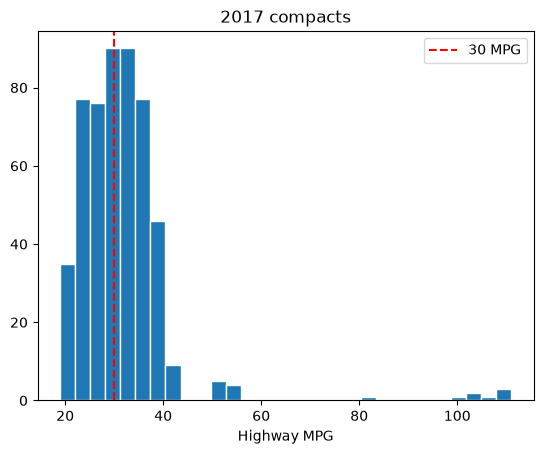

n = 517, mean = 31.99, t = 4.20, p = 0.000015
Reject H0 at 0.05? True
Distinct make+model combos: 90
count    90.000000
mean      5.744444
std       4.798317
min       1.000000
25%       2.000000
50%       5.000000
75%       7.750000
max      27.000000
dtype: float64
make        model   
Toyota      Tacoma      27
Chevrolet   Corvette    24
Nissan      Frontier    22
            370Z        17
Porsche     911         14
Honda       Civic       13
Audi        A3          12
Buick       Encore      10
Volkswagen  Golf GTI    10
Chevrolet   Sonic       10
dtype: int64
n = 90, mean = 35.62, t = 3.10, p = 0.001310


In [ ]:
#H₀ The true average highway MPG of 2017 compacts is 30
#Hₐ The true average is over 30, which is marketing's claim.
# One-sided since marketing only claims over 30, so only evidence of a mean > 30 supports it.

# b) sample: 2017 compact cars (MPG you trust); n, mean, histogram
compacts = cars_2017[cars_2017['vehicle_size'] == 'Compact']['highway_mpg'].dropna()

print("n:", len(compacts))
print(compacts.describe())
print("skew:", compacts.skew())

plt.hist(compacts, bins=30, edgecolor='white')
plt.axvline(30, color='red', linestyle='--', label='30 MPG')
plt.xlabel('Highway MPG')
plt.title('2017 compacts')
plt.legend()
plt.show()

#The distribution is right-skewed: most compacts fall between 20 and 42 MPG,
# with a small tail of high-MPG outliers (50-110), likely electric/hybrid vehicles.
# Because n is large, the CLT makes the t-test reasonable even if the data isn't normal,
# though the outliers pull the mean up, so I also checked the median.

# c) one-sample t-test vs 30

t_stat, p_val = stats.ttest_1samp(compacts, 30, alternative='greater')

print(f"n = {len(compacts)}, mean = {compacts.mean():.2f}, t = {t_stat:.2f}, p = {p_val:.6f}")
print("Reject H0 at 0.05?", p_val < 0.05)

#H₀ is rejected With n = 517, mean = 31.99, t = 4.20 and p = 0.000015, p is far below 0.05.
#There is strong statistical evidence that 2017 compacts average more than 30 highway MPG, so marketing's claim is supported.

# d) rows per make+model, then one row per model and retest

compacts_df = cars_2017[cars_2017['vehicle_size'] == 'Compact'].dropna(subset=['highway_mpg'])

rows_per_model = compacts_df.groupby(['make', 'model']).size().sort_values(ascending=False)
print("Distinct make+model combos:", len(rows_per_model))
print(rows_per_model.describe())
print(rows_per_model.head(10))

per_model = compacts_df.groupby(['make', 'model'])['highway_mpg'].mean()
t2, p2 = stats.ttest_1samp(per_model, 30, alternative='greater')
print(f"n = {len(per_model)}, mean = {per_model.mean():.2f}, t = {t2:.2f}, p = {p2:.6f}")

# d) 517 rows come from only 90 models, and trims of the same model are not independent.
#Per-model: n 517 -> 90, mean 31.99 -> 35.62, t 4.20 -> 3.10, p 0.000015 -> 0.0013. Still significant.
#I trust the per-model test more because it meets the independence assumption. The claim holds either way.


**Answer:** 

### Q6. Do manual cars cost less? (the big one)

A sales rep says: *"Manual cars are way cheaper. We should push manuals to budget shoppers."*

Compare `AUTOMATIC` vs `MANUAL` only.

a) Compare the median MSRP of the two groups.

b) Before believing it, compare the `year` of manual vs automatic cars. What do you notice?

c) Redo (a) using only 2015–2017 cars, then within each `vehicle_size`. For 2015–17 compacts, use the Mann–Whitney U test (`stats.mannwhitneyu(auto, manual)`) to compare prices.

- What do the p-value and medians suggest?

d) Write one sentence back to the sales rep.

In [ ]:
# a) compare median MSRP by transmission type
tm = clean[clean['transmission_type'].isin(['AUTOMATIC', 'MANUAL'])]
print(tm.groupby('transmission_type')['msrp'].agg(['count', 'median']))

# b) compare year by transmission type

print(tm.groupby('transmission_type')['year'].agg(['count', 'median', 'mean', 'min', 'max']))
print(pd.crosstab(tm['year'], tm['transmission_type'])) 

# b) Manuals are mostly older (median year 2008) than automatics (median year 2015).
# Older cars cost less no matter the transmission, so the $13.6k price gap above
# is partly just about age. That makes the comparison unfair.

# c) compare 2015-2017 medians overall and within each vehicle_size

recent = tm[tm['year'].between(2015, 2017)]
print(recent.groupby('transmission_type')['msrp'].agg(['count', 'median']))
print(recent.groupby(['vehicle_size', 'transmission_type'])['msrp'].agg(['count', 'median']).unstack())

# For 2015-17 compacts, test automatic vs manual prices with:

comp = recent[recent['vehicle_size'] == 'Compact']
auto = comp.loc[comp['transmission_type'] == 'AUTOMATIC', 'msrp']
manual = comp.loc[comp['transmission_type'] == 'MANUAL', 'msrp']
u_stat, p_val = stats.mannwhitneyu(auto, manual, alternative='greater')  # H_a: automatics cost more
print(f"auto n = {len(auto)}, median = {auto.median():,.0f}")
print(f"manual n = {len(manual)}, median = {manual.median():,.0f}")
print(f"U = {u_stat:.1f}, p = {p_val:.6f}")

# stats.mannwhitneyu(auto, manual)

                   count   median
transmission_type                
AUTOMATIC           7928  33007.5
MANUAL              2633  19385.0
                   count  median         mean   min   max
transmission_type                                        
AUTOMATIC           7928  2015.0  2011.843340  1990  2017
MANUAL              2633  2008.0  2006.475503  1990  2017
transmission_type  AUTOMATIC  MANUAL
year                                
1990                      40      37
1991                      47      54
1992                      39      88
1993                      44     114
1994                      42      87
1995                      59      58
1996                      54      61
1997                      60     104
1998                      51      94
1999                      55      57
2000                      54      56
2001                     100      68
2002                     144      58
2003                     152      80
2004                     165      63
200

**Answer:**

### Q7. Significant ≠ important

Among cars whose MPG you trust, 4-door cars get better highway MPG than 2-door cars.

a) Run a Welch t-test. Report the difference in means and the p-value.

b) Translate the difference into dollars. Assume 12,000 miles/year and \$3.50/gallon. How much does the average 4-door driver save per year?

c) Now pretend you only had **30 cars per group.** Draw 30 random 4-door and 30 random 2-door cars, run the same test, and repeat 1,000 times. What fraction of those tests come out significant (p < 0.05)?

d) Would you put "4-door cars are significantly more fuel-efficient" in an ad? What would you say instead?

In [27]:
# a) Welch t-test, 4-door vs 2-door
four = clean.loc[clean['number_of_doors'] == 4, 'highway_mpg'].dropna()
two  = clean.loc[clean['number_of_doors'] == 2, 'highway_mpg'].dropna()

t_stat, p_val = stats.ttest_ind(four, two, equal_var=False)   # equal_var=False = Welch
diff = four.mean() - two.mean()
print(f"4-door n = {len(four)}, mean = {four.mean():.2f}")
print(f"2-door n = {len(two)}, mean = {two.mean():.2f}")
print(f"difference = {diff:.2f} MPG, t = {t_stat:.2f}, p = {p_val:.6g}")

# b) yearly gas cost = miles * price_per_gallon / mpg
miles, ppg = 12000, 3.50
cost_four = miles * ppg / four.mean()
cost_two  = miles * ppg / two.mean()
print(f"4-door: ${cost_four:,.0f}/yr, 2-door: ${cost_two:,.0f}/yr, "
      f"savings = ${cost_two - cost_four:,.0f}/yr")

# c) simulation: 
rng = np.random.default_rng(42)
n_sims, hits = 1000, 0
for _ in range(n_sims):
    s4 = rng.choice(four, 30, replace=False)
    s2 = rng.choice(two, 30, replace=False)
    _, p = stats.ttest_ind(s4, s2, equal_var=False)
    if p < 0.05:
        hits += 1
print(f"Fraction significant with n = 30 per group: {hits / n_sims:.3f}")
# 30 cars per group, repeated 1,000 times

4-door n = 7955, mean = 27.33
2-door n = 2876, mean = 25.34
difference = 1.99 MPG, t = 12.90, p = 1.28694e-37
4-door: $1,537/yr, 2-door: $1,658/yr, savings = $121/yr
Fraction significant with n = 30 per group: 0.137


**Answer:**

---
## Part 5: Communicate

### Q8. Your memo to the pricing manager

Write 4–6 sentences. Include:
- Your answer to "do manual cars cost less?", with at least one number
- One other finding from this notebook that matters for pricing
- One limitation of this data a manager should know about

No unexplained jargon: if you say "significant," say what it means.

**Memo:**

---
## 🚀 Stretch (optional)

### 🚀 S1. Horsepower and price

a) Compute the correlation between `engine_hp` and `msrp` three ways: Pearson, Pearson with `np.log10(msrp)`, and Spearman. Why do they differ?

b) Scatter plot HP vs MSRP with a log y-axis (`plt.yscale("log")`).

c) Does adding horsepower *cause* a higher price? Name one lurking variable.

In [ ]:
# S1

### 🚀 S2. Is transmission tied to vehicle size?

For 2015–2017 cars (automatic and manual only), build a crosstab of `vehicle_size` × `transmission_type` and run a chi-square test (`stats.chi2_contingency`). How does this connect to Q6?

In [ ]:
# S2